# Joint parameter accuracy versus query time

For each family, draw **A=8 parameters uniformly from the original parameter box**, and **R=16 independent observation datasets per parameter**. Reuse each dataset unchanged across 17 physical query times in [0,4]. Models trained at n=8 and 128 are evaluated at their respective training n, at M=2^19 and the original two seeds.

The metric is **all-token normalized parameter MSE**, averaged over tokens and parameter coordinates, then equally over datasets, parameters, and model seeds. Birth–death instead reports the MSE of the identifiable pair (b−d, c) in physical units, computed per token from the decoded parameter estimate, as in the statistical comparisons. This tests query-dependent accuracy, not equality of outputs or parameter identifiability.

Fresh diagnostic datasets use the original unsorted uniform observation times on [0,3.2], exact trajectories, state scales, and normalized noise q=0.02. The same anchors and datasets are used across model seeds; n=8 observations are prefixes of n=128 observations. Only the broadcast query changes within a sweep. No training or statistical optimization is performed. This notebook is independent of the conditional-variance experiment.

Inference is cached per model/settings under `statistical_comparison_cache/joint_query_sweep/`, including the parameters, observation datasets, and coordinate errors for every query. Figures save to `figures/joint_query_sweep/`. Curves are averages, without confidence bands; A and R are deliberately modest exploratory settings.


In [19]:
from pathlib import Path
import sys, json, hashlib, os
import numpy as np
import torch
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT/'src'/'ode_paper').exists(): ROOT = ROOT.parent
if not (ROOT/'src'/'ode_paper').exists(): raise RuntimeError('Open from Paper repo or its notebooks folder.')
sys.path.insert(0, str(ROOT/'src'))
from ode_paper.joint import Config, Transformer
from ode_paper.families import SPECS, bounds, encode, decode, solution
from ode_paper.config import fingerprint
from ode_paper.local_results import checked_path
import importlib
import ode_paper.paper_style as _paper_style
importlib.reload(_paper_style)
from ode_paper.paper_style import apply_style, PANEL_SIZE
apply_style()
plt.rcParams.update({'axes.labelsize': 10, 'axes.titlesize': 10, 'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 8})

SEEDS = (20260906, 20260907)
TRAIN_NS = (8, 128)
A, R = 8, 16
TAUS = np.linspace(0., 4., 17)  # Physical query times; input uses tau/4.
DIAGNOSTIC_SEED = 20261105
DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
BATCH_SIZE = 32
CACHE_ROOT = ROOT/'statistical_comparison_cache'/'joint_query_sweep'
OUTPUT = ROOT/'figures'/'joint_query_sweep'
print('Device:', DEVICE, '| fixed parameters:', A, '| datasets per parameter:', R)


Device: mps | fixed parameters: 8 | datasets per parameter: 16


In [20]:
def observations(family):
    if A < 1 or R < 2: raise ValueError('Use A>=1 and R>=2.')
    family_index = tuple(SPECS).index(family)
    rng = np.random.default_rng(np.random.SeedSequence([DIAGNOSTIC_SEED, family_index]))
    lo, hi = bounds(family)
    theta = rng.uniform(lo, hi, size=(A, len(lo)))
    repeated = np.repeat(theta, R, axis=0)
    times = rng.uniform(0, .8, size=(A*R, 128))
    states = solution(repeated, times, family)/np.asarray(SPECS[family]['scale'])
    states += .02*rng.standard_normal(states.shape)
    points = np.concatenate((times[...,None], states), axis=-1).astype(np.float32)
    return theta, points, encode(repeated, family)


def model_spec(family, seed, train_n):
    base = (ROOT/'evaluation_cache_downloads'/f'seed_{seed}').resolve()
    catalog = json.loads((base/'joint_catalog.json').read_text())
    if catalog['seed'] != seed or catalog['format_version'] != 1: raise ValueError('Invalid catalog')
    entries = [e for e in catalog['evaluations'] if e['group']=='joint_experiment'
               and e['config']['family']==family and e['config']['task']=='joint'
               and e['config']['seed']==seed and e['config']['n']==train_n and e['config']['M']==2**19]
    runs = {e['run'] for e in entries}
    if len(runs)!=1: raise ValueError(f'Missing/ambiguous model: {family}, {seed}, {train_n}')
    cfg = Config(**entries[0]['config'])
    if cfg.q != .02: raise ValueError('Noise mismatch')
    path = checked_path(base, next(iter(runs))+'/best.pt')
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != catalog['sha256'][path.relative_to(base).as_posix()]: raise ValueError('Checkpoint checksum mismatch')
    return cfg, path, digest


def query_errors(family, seed, train_n, theta, points, targets):
    if train_n not in (8,128): raise ValueError('This diagnostic uses train n=8 or 128.')
    if np.any(TAUS<0) or np.any(TAUS>4): raise ValueError('Query times must lie in [0,4].')
    cfg, path, digest = model_spec(family, seed, train_n)
    source = hashlib.sha256()
    for name in ('families.py','model.py','joint.py'):
        source.update((ROOT/'src'/'ode_paper'/name).read_bytes())
    identity = dict(version=1, config=cfg.to_dict(), checkpoint=digest, source=source.hexdigest(),
                    A=A,R=R,taus=TAUS.tolist(),diagnostic_seed=DIAGNOSTIC_SEED,device=DEVICE,
                    batch_size=BATCH_SIZE,points=hashlib.sha256(points.tobytes()).hexdigest(),
                    theta=hashlib.sha256(theta.tobytes()).hexdigest(),metric='identifiable_pair_physical_all_token' if family=='birth_death' else 'normalized_parameter_all_token')
    folder=CACHE_ROOT/family
    cache=folder/f'{fingerprint(identity)}.npz'
    if cache.exists():
        with np.load(cache,allow_pickle=False) as saved:
            if not (np.array_equal(saved['theta'],theta) and np.array_equal(saved['taus'],TAUS)
                    and np.array_equal(saved['points'],points[:,:train_n])):
                raise ValueError('Cached diagnostic data mismatch')
            errors=saved['coordinate_errors'].copy()
        print(f'Loaded {family}, seed={seed}, train n={train_n}')
    else:
        raw=torch.load(path,map_location='cpu',weights_only=False)
        model=Transformer(cfg).to(DEVICE)
        model.load_state_dict(raw['model']);model.eval()
        p=targets.shape[1]
        q=2 if family=='birth_death' else p  # birth-death: identifiable pair (b-d, c), physical units
        true=np.repeat(theta,R,axis=0)
        errors=np.empty((A*R,len(TAUS),q))
        with torch.inference_mode():
            for ti,tau in enumerate(TAUS):
                data=np.concatenate((points[:,:train_n],np.full((A*R,train_n,1),tau/4,dtype=np.float32)),axis=-1)
                for start in range(0,A*R,BATCH_SIZE):
                    stop=min(start+BATCH_SIZE,A*R)
                    x=torch.as_tensor(data[start:stop],dtype=torch.float32,device=DEVICE)
                    pred=model(x)[...,:p].cpu().numpy().astype(float)
                    if family=='birth_death':
                        phys=decode(pred,family)
                        t0=true[start:stop,None,:]
                        diff=np.stack(((phys[...,0]-phys[...,1])-(t0[...,0]-t0[...,1]),phys[...,2]-t0[...,2]),axis=-1)
                        errors[start:stop,ti]=(diff**2).mean(axis=1)
                    else:
                        errors[start:stop,ti]=((pred-targets[start:stop,None,:])**2).mean(axis=1)
        errors=errors.reshape(A,R,len(TAUS),q)
        if not np.isfinite(errors).all(): raise FloatingPointError('Nonfinite inference errors')
        folder.mkdir(parents=True,exist_ok=True)
        temp=cache.with_suffix('.building.npz')
        np.savez_compressed(temp,coordinate_errors=errors,theta=theta,points=points[:,:train_n],taus=TAUS)
        os.replace(temp,cache)
        cache.with_suffix('.json').write_text(json.dumps(identity,indent=2))
        print(f'Computed and saved {family}, seed={seed}, train n={train_n}')
    if errors.shape!=(A,R,len(TAUS),2 if family=='birth_death' else targets.shape[1]) or not np.isfinite(errors).all() or np.any(errors<0):
        raise ValueError('Invalid cached errors')
    return errors


def plot_family(family, ax=None):
    standalone=ax is None
    theta,points,targets=observations(family)
    results={}
    if standalone: fig,ax=plt.subplots(figsize=PANEL_SIZE)
    for train_n in TRAIN_NS:
        by_seed=[query_errors(family,seed,train_n,theta,points,targets) for seed in SEEDS]
        results[train_n]=dict(theta=theta,coordinate_errors_by_seed=dict(zip(SEEDS,by_seed)))
        # Equal averages: coordinates, datasets, parameters, then model seeds.
        mean=np.mean([e.mean(axis=(0,1,3)) for e in by_seed],axis=0)
        ax.plot(TAUS,mean,marker='o',linestyle='--' if train_n==8 else '-', label=f'n={train_n}')
    ax.set(xlabel='Query time τ',ylabel='MSE of (b-d,c)' if family=='birth_death' else 'Normalized MSE',
           title=r'$\tau$ dependence in joint model for '+{'forced_linear':'Forced linear','logistic':'Logistic growth',
                                                          'birth_death':'Birth–death','stuart_landau':'Stuart–Landau'}[family])
    ax.grid(alpha=.2)
    if standalone:
        ax.legend(loc='best');fig.tight_layout()
        OUTPUT.mkdir(parents=True,exist_ok=True)
        for ext in ('png','pdf'):fig.savefig(OUTPUT/f'{family}_parameter_mse_vs_tau.{ext}',dpi=180,bbox_inches='tight')
        plt.show()
    return results


GRID_FAMILIES=('forced_linear','logistic','birth_death','stuart_landau')
GRID_SIZE=(8.0,4.6)

def plot_grid():
    """One 2x2 figure (a panel per family) with a single shared legend below."""
    fig,axes=plt.subplots(2,2,figsize=GRID_SIZE)
    results={}
    for ax,family in zip(axes.flat,GRID_FAMILIES):
        results[family]=plot_family(family,ax=ax)
    for ax in axes[0]: ax.set_xlabel('')
    handles,labels=axes.flat[0].get_legend_handles_labels()
    fig.tight_layout()
    fig.canvas.draw()
    below=min(ax.get_tightbbox().transformed(fig.transFigure.inverted()).y0 for ax in axes[-1])  # bottom of x-axis labels
    fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,below-.004),ncol=len(labels),fontsize=8,
               handlelength=1.8,columnspacing=1.0,handletextpad=.5,framealpha=.95)
    OUTPUT.mkdir(parents=True,exist_ok=True)
    for ext in ('png','pdf'):fig.savefig(OUTPUT/f'parameter_mse_vs_tau.{ext}',dpi=180,bbox_inches='tight')
    return results


## Combined figure (2×2)


Loaded forced_linear, seed=20260906, train n=8
Loaded forced_linear, seed=20260907, train n=8
Loaded forced_linear, seed=20260906, train n=128
Loaded forced_linear, seed=20260907, train n=128
Loaded logistic, seed=20260906, train n=8
Loaded logistic, seed=20260907, train n=8
Loaded logistic, seed=20260906, train n=128
Loaded logistic, seed=20260907, train n=128
Loaded birth_death, seed=20260906, train n=8
Loaded birth_death, seed=20260907, train n=8
Loaded birth_death, seed=20260906, train n=128
Loaded birth_death, seed=20260907, train n=128
Loaded stuart_landau, seed=20260906, train n=8
Loaded stuart_landau, seed=20260907, train n=8
Loaded stuart_landau, seed=20260906, train n=128
Loaded stuart_landau, seed=20260907, train n=128


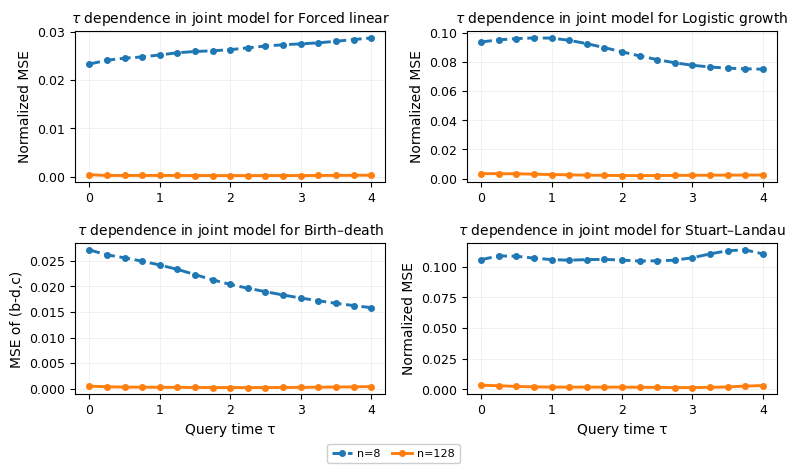

In [21]:
query_results = plot_grid()
plt.show()
